# Good Health and Well-being: Machine Learning Classification and Regression

### Team members
* Harshini Ramdas Bhandary (PRN: 202401040151) (Roll no: 35)
* Parth Nandkishor Shingane (PRN: 202401040210) (Roll no: 51)
* Dhruv Prafull Bompilwar (PRN: 202401040200) (Roll no: 49)

### Activity No. 1: Machine Learning Classification and Regression

In the first assignment we collected World Bank data for the UN Sustainable Development Goal 3 (Good Health and Well-being), cleaned it and built new features. In this assignment we use that same engineered dataset sdg3_health_engineered.csv to train real machine learning models.



## 1. Setup and loading the data

In [ ]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             confusion_matrix, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

The notebook needs the file `sdg3_health_engineered.csv` from the first assignment. If you run this on Google Colab and the file is not there, the next cell will ask you to upload it. If you run it on your own computer, keep the csv in the same folder as this notebook.

In [ ]:
import os
CSV_NAME = "sdg3_health_engineered.csv"

if not os.path.exists(CSV_NAME):
    try:
        from google.colab import files          # only works on Colab
        print("Please upload", CSV_NAME)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_NAME} in the same folder as this notebook.")

df = pd.read_csv(CSV_NAME)
print("Shape:", df.shape)
print("Countries:", df.country.nunique(), "| Years:", df.year.min(), "to", df.year.max())
print("Missing values left:", int(df.isna().sum().sum()))
df[["country", "year", "life_expectancy", "infant_mortality_per_1000", "gdp_per_capita_usd", "income_group"]].head()

Shape: (11915, 64)
Countries: 217 | Years: 1970 to 2024
Missing values left: 0


,country,year,life_expectancy,infant_mortality_per_1000,gdp_per_capita_usd,income_group
0,Afghanistan,1970,38.9531,166.558,190.690145,Low income
1,Afghanistan,1971,38.9531,166.558,190.690145,Low income
2,Afghanistan,1972,38.9531,166.558,190.690145,Low income
3,Afghanistan,1973,38.9531,166.558,190.690145,Low income
4,Afghanistan,1974,39.4690,166.558,190.690145,Low income


## 2. Choosing the features

We want models that can **predict a country's health outcome from the things a government can actually measure**: money spent on health, doctors and hospital beds, clean water and sanitation, income, urbanisation, vaccination and so on.

For that reason we keep only the following columns as inputs (`X`):

* `health_expenditure_pct_gdp`, `log_health_exp_pc`: how much is spent on health
* `physicians_per_1000`, `hospital_beds_per_1000`: health system capacity
* `basic_sanitation_pct`, `basic_drinking_water_pct`: water and sanitation access
* `measles_immunization_pct`: vaccine access
* `log_gdp_per_capita`, `unemployment_pct`, `urban_population_pct`, `log_population`: economy and population
* `birth_rate_per_1000`: demographic factor
* `years_since_1970`: time trend

**Columns we deliberately leave out**

We do not use `infant_mortality_per_1000`, `death_rate_per_1000`, `life_exp_rolling5`, `life_exp_yoy_change`, `life_exp_equal_width`, `country_target_enc` and similar columns. These are either another health *outcome* or are built directly from life expectancy. If we left them in, the model would just be copying the answer, and the scores would look great but mean nothing (this is called data leakage).

In [ ]:
FEATURES = [
    "health_expenditure_pct_gdp", "log_health_exp_pc",
    "physicians_per_1000", "hospital_beds_per_1000",
    "basic_sanitation_pct", "basic_drinking_water_pct", "measles_immunization_pct",
    "log_gdp_per_capita", "unemployment_pct", "urban_population_pct", "log_population",
    "birth_rate_per_1000", "years_since_1970",
]
print(len(FEATURES), "input features")
df[FEATURES].describe().T.round(2)

13 input features


,count,mean,std,min,25%,50%,75%,max
health_expenditure_pct_gdp,11915.0,5.93,1.87,2.04,4.88,5.77,6.56,12.74
log_health_exp_pc,11915.0,5.54,1.38,2.40,4.84,5.60,6.24,8.80
physicians_per_1000,11915.0,1.37,1.29,0.02,0.23,1.03,2.24,5.17
hospital_beds_per_1000,11915.0,3.75,3.09,0.25,1.42,2.95,5.40,14.60
basic_sanitation_pct,11915.0,78.35,24.98,8.70,78.22,87.38,93.48,100.00
basic_drinking_water_pct,11915.0,89.03,14.92,36.59,90.36,94.42,97.56,100.00
measles_immunization_pct,11915.0,71.13,26.64,5.00,53.00,80.00,94.00,99.00
log_gdp_per_capita,11915.0,7.96,1.65,4.78,6.59,7.94,9.24,11.41
unemployment_pct,11915.0,7.38,4.70,0.72,4.79,6.50,7.91,26.18
urban_population_pct,11915.0,54.29,25.17,8.09,33.24,54.24,74.12,100.00


## 3. Train / test split

Our data has many rows for the same country (one for every year). Rows of the same country look very similar to each other. If we split the rows at random, Afghanistan 1995 could be in the training set and Afghanistan 1996 in the test set, and the model would get an easy test.

To keep the test honest we split **by country**: 80% of countries go to training and the other 20% are completely unseen during training. This shows how the model behaves on a *new* country, which is what we care about.

In [ ]:
groups = df["country"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=groups))

train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Training rows:", len(train_df), "from", train_df.country.nunique(), "countries")
print("Testing rows :", len(test_df),  "from", test_df.country.nunique(),  "countries")
print("Countries shared between train and test:", len(set(train_df.country) & set(test_df.country)))

Training rows: 9495 from 173 countries
Testing rows : 2420 from 44 countries
Countries shared between train and test: 0


# Part A: Classification

## 4. Defining the classification problem

**Question:** Can we tell, from health-system and economic indicators, whether a country in a given year has a *good* life expectancy?

We turn `life_expectancy` into two classes:

* **1 = Good**, life expectancy is 70 years or more
* **0 = Not good**, life expectancy is below 70 years

70 years is close to the global average and is also a commonly used benchmark, so it splits the data into two groups of about the same size.

Share of 'Good' class  -> train: 47.1%   test: 47.8%


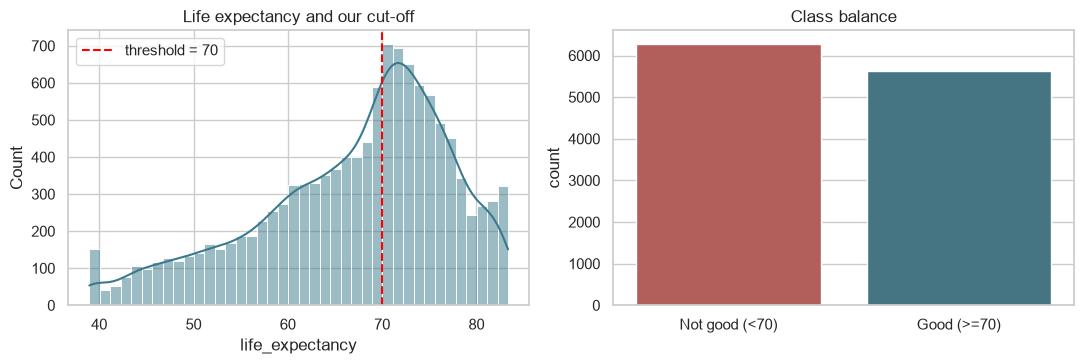

In [ ]:
THRESHOLD = 70
y_train = (train_df["life_expectancy"] >= THRESHOLD).astype(int).values
y_test  = (test_df["life_expectancy"]  >= THRESHOLD).astype(int).values
X_train, X_test = train_df[FEATURES].values, test_df[FEATURES].values

print("Share of 'Good' class  -> train: %.1f%%   test: %.1f%%" % (y_train.mean()*100, y_test.mean()*100))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["life_expectancy"], bins=40, kde=True, ax=ax[0], color="#3b7a8c")
ax[0].axvline(THRESHOLD, color="red", ls="--", label=f"threshold = {THRESHOLD}")
ax[0].set_title("Life expectancy and our cut-off"); ax[0].legend()
sns.countplot(x=np.r_[y_train, y_test], ax=ax[1], palette=["#c0504d", "#3b7a8c"])
ax[1].set_xticklabels(["Not good (<70)", "Good (>=70)"]); ax[1].set_title("Class balance"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

The two classes are nearly balanced, so accuracy is a fair metric here. We will still look at precision, recall, F1 and loss as the assignment asks.

## 5. Training the four models

All four models are put into a `Pipeline` together with a `StandardScaler`. The scaler is fitted **only on the training data** inside the pipeline, so no information from the test set leaks in. Scaling is a must for SVM and KNN because they work with distances. Decision Tree and Naive Bayes do not need it, but using the same pipeline for everyone keeps the comparison simple and fair.

We also tune one or two important settings of each model with a grid search. Cross-validation is done with `GroupKFold`, which again keeps every country in only one fold.

| Model | Settings we tune |
|---|---|
| SVM (RBF kernel) | `C`, `gamma` |
| Decision Tree | `max_depth`, `min_samples_leaf` |
| KNN | `n_neighbors`, `weights` |
| Gaussian Naive Bayes | `var_smoothing` |

In [ ]:
models_and_grids = {
    "SVM": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
            {"clf__C": [0.5, 1, 5, 10], "clf__gamma": ["scale", 0.01, 0.05]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 9, 15, 25], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(),
            {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),
}

cv = GroupKFold(n_splits=5)
best_models, train_times = {}, {}

for name, (est, grid) in models_and_grids.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", est)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
    t0 = time.time()
    search.fit(X_train, y_train, groups=groups_train)
    train_times[name] = time.time() - t0
    best_models[name] = search.best_estimator_
    print(f"{name:14s} best CV F1 = {search.best_score_:.4f} | best settings = {search.best_params_} | time = {train_times[name]:.1f}s")

SVM            best CV F1 = 0.8935 | best settings = {'clf__C': 0.5, 'clf__gamma': 0.05} | time = 13.8s


Decision Tree  best CV F1 = 0.8757 | best settings = {'clf__max_depth': 5, 'clf__min_samples_leaf': 1} | time = 0.4s


KNN            best CV F1 = 0.8793 | best settings = {'clf__n_neighbors': 25, 'clf__weights': 'uniform'} | time = 0.3s
Naive Bayes    best CV F1 = 0.8693 | best settings = {'clf__var_smoothing': 0.1} | time = 0.0s


## 6. Evaluating the models

Metrics we use (positive class = "Good life expectancy"):

* **Accuracy**: share of all predictions that are correct.
* **Precision**: out of the countries the model called "Good", how many really are Good.
* **Recall**: out of all countries that really are Good, how many the model found.
* **F1-score**: one number that balances precision and recall.
* **Loss (log loss)**: it uses the predicted *probability*, not only the final label. A model that is confidently wrong is punished heavily. Lower is better.
* **ROC-AUC**: extra metric showing how well the model separates the two classes at every threshold.

We calculate them on both the training and the test set. A big gap between the two means the model is overfitting.

In [ ]:
def classification_report_row(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall":    recall_score(y, pred),
        "F1-score":  f1_score(y, pred),
        "Log loss":  log_loss(y, prob),
        "ROC-AUC":   roc_auc_score(y, prob),
    }

test_rows, train_rows = {}, {}
for name, model in best_models.items():
    test_rows[name]  = classification_report_row(model, X_test,  y_test)
    train_rows[name] = classification_report_row(model, X_train, y_train)

test_table  = pd.DataFrame(test_rows).T
train_table = pd.DataFrame(train_rows).T

print("TEST SET (countries the models have never seen)")
display(test_table.round(4).style.highlight_max(subset=["Accuracy","Precision","Recall","F1-score","ROC-AUC"], color="#b7e4c7")
        .highlight_min(subset=["Log loss"], color="#b7e4c7"))
print("TRAINING SET")
display(train_table.round(4))

TEST SET (countries the models have never seen)


,Accuracy,Precision,Recall,F1-score,Log loss,ROC-AUC
SVM,0.907000,0.889500,0.919600,0.904300,0.226200,0.967200
Decision Tree,0.874800,0.829300,0.929100,0.876400,0.490200,0.949500
KNN,0.868600,0.851500,0.878000,0.864600,0.767000,0.943600
Naive Bayes,0.884300,0.835900,0.942900,0.886200,0.645200,0.953500


TRAINING SET


,Accuracy,Precision,Recall,F1-score,Log loss,ROC-AUC
SVM,0.9202,0.9007,0.9334,0.9168,0.1868,0.9792
Decision Tree,0.9284,0.9116,0.9390,0.9251,0.1900,0.9744
KNN,0.9402,0.9240,0.9513,0.9374,0.1367,0.9898
Naive Bayes,0.8763,0.8340,0.9204,0.8751,0.6543,0.9448


In [ ]:
# how big is the train -> test drop for each model?
gap = (train_table[["Accuracy", "F1-score"]] - test_table[["Accuracy", "F1-score"]]).round(4)
gap.columns = ["Accuracy drop (train - test)", "F1 drop (train - test)"]
gap

,Accuracy drop (train - test),F1 drop (train - test)
SVM,0.0131,0.0125
Decision Tree,0.0536,0.0487
KNN,0.0716,0.0729
Naive Bayes,-0.0080,-0.0111


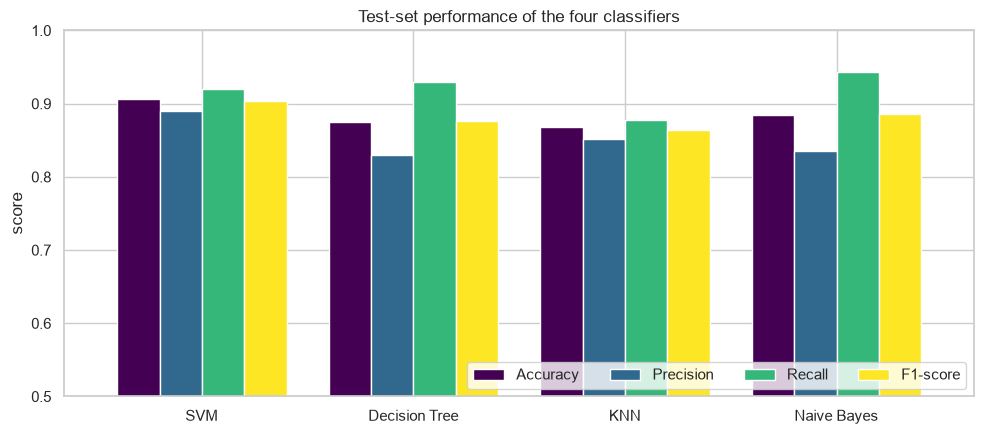

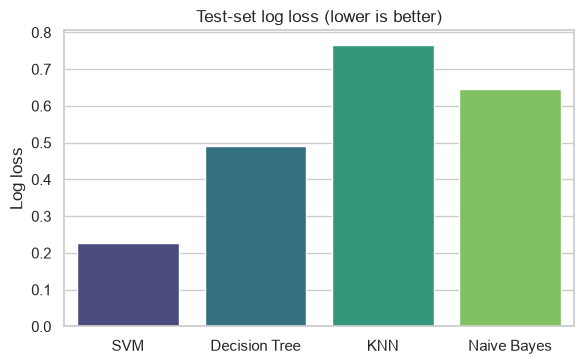

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
test_table[metrics].plot(kind="bar", figsize=(10, 4.5), width=0.8, colormap="viridis")
plt.ylim(0.5, 1.0); plt.xticks(rotation=0); plt.ylabel("score")
plt.title("Test-set performance of the four classifiers")
plt.legend(loc="lower right", ncol=4); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.8))
sns.barplot(x=test_table.index, y=test_table["Log loss"], palette="viridis")
plt.title("Test-set log loss (lower is better)"); plt.xlabel(""); plt.tight_layout(); plt.show()

### 6.1 Confusion matrices

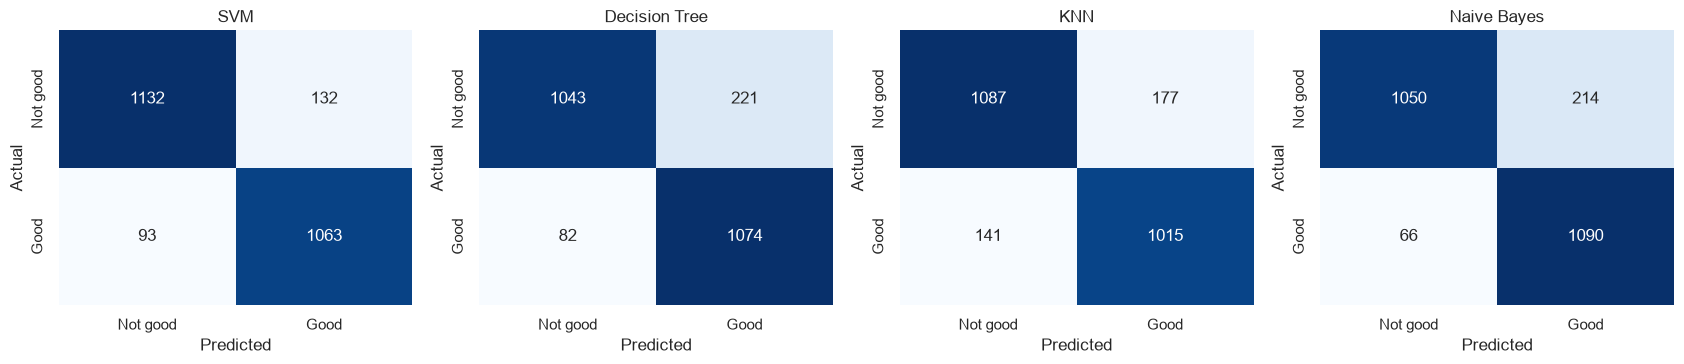

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

Reading a confusion matrix: the top-right box is *false positives* (we said "Good" but the country is not) and the bottom-left box is *false negatives* (we said "Not good" but the country is actually Good). Precision is hurt by the first kind of mistake and recall by the second.

### 6.2 ROC curves

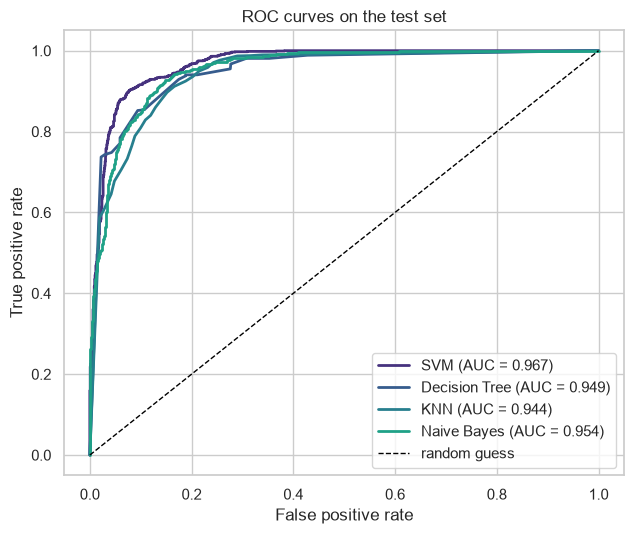

In [ ]:
plt.figure(figsize=(6.5, 5.5))
for name, model in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {test_table.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 6.3 Is the result stable? (Cross-validation)

One test split can be lucky or unlucky. So we also run 5-fold grouped cross-validation on the training data for each tuned model and look at the average and the spread of the F1-score.

,Mean F1,Std dev,Worst fold,Best fold
SVM,0.8935,0.0221,0.8578,0.9193
Decision Tree,0.8757,0.0254,0.8409,0.9127
KNN,0.8793,0.0210,0.8445,0.9049
Naive Bayes,0.8693,0.0338,0.8291,0.9219


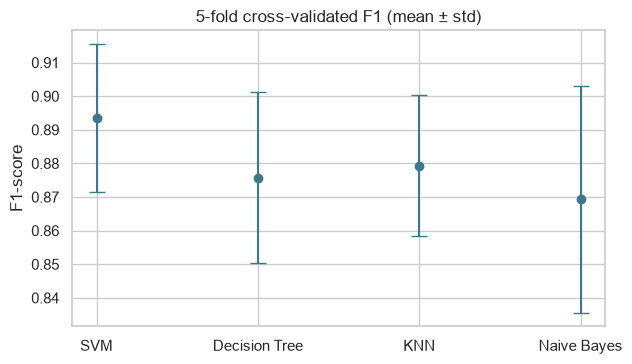

In [ ]:
cv_rows = {}
for name, model in best_models.items():
    scores = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_rows[name] = {"Mean F1": scores.mean(), "Std dev": scores.std(), "Worst fold": scores.min(), "Best fold": scores.max()}
cv_table = pd.DataFrame(cv_rows).T
display(cv_table.round(4))

plt.figure(figsize=(6.5, 3.8))
plt.errorbar(cv_table.index, cv_table["Mean F1"], yerr=cv_table["Std dev"], fmt="o", capsize=6, color="#3b7a8c")
plt.ylabel("F1-score"); plt.title("5-fold cross-validated F1 (mean ± std)"); plt.tight_layout(); plt.show()

## 7. Looking inside each model

Here we check a few extra things that explain *why* the models behave the way they do.

### 7.1 Decision Tree: what rules did it learn?

Chosen depth: 5 | number of leaves: 31


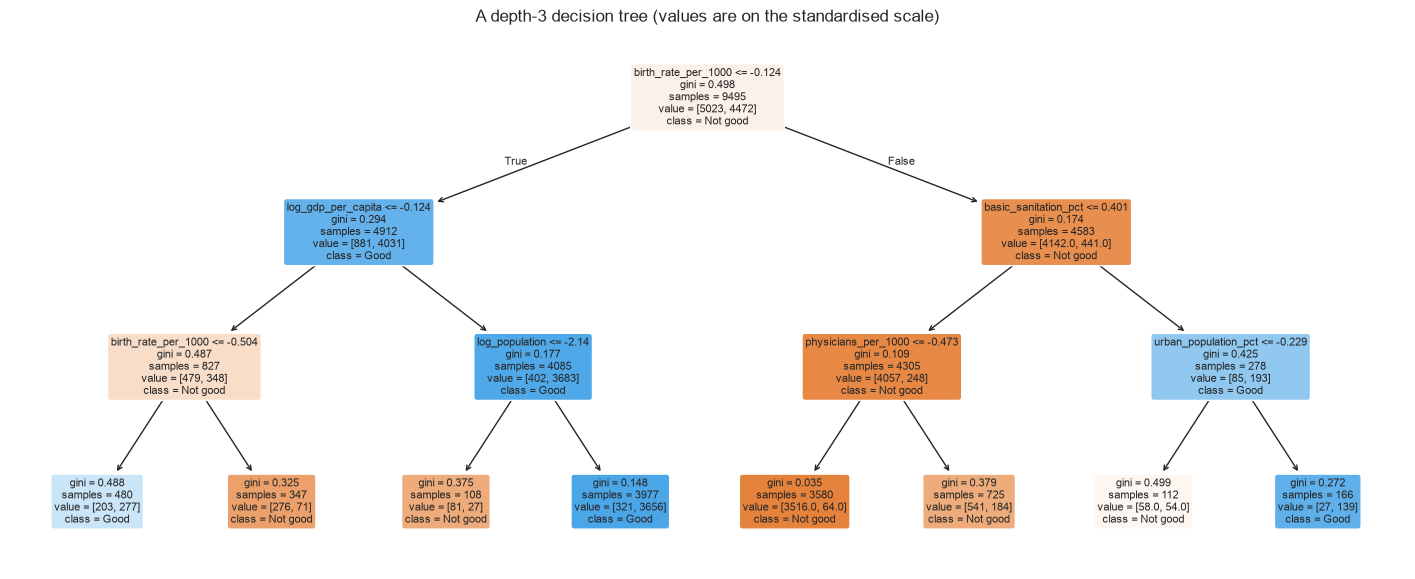

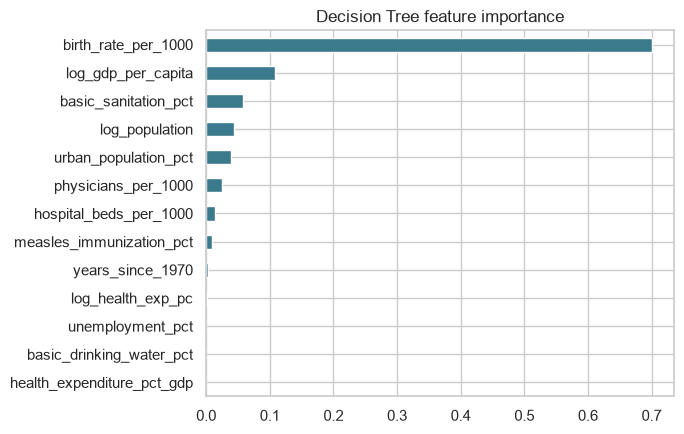

In [ ]:
tree_model = best_models["Decision Tree"].named_steps["clf"]
print("Chosen depth:", tree_model.get_depth(), "| number of leaves:", tree_model.get_n_leaves())

# a small tree on the same data, only so that we can read it easily
small_tree = Pipeline([("scale", StandardScaler()), ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(small_tree.named_steps["clf"], feature_names=FEATURES, class_names=["Not good", "Good"],
          filled=True, rounded=True, fontsize=8)
plt.title("A depth-3 decision tree (values are on the standardised scale)"); plt.show()

imp = pd.Series(tree_model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4.5), color="#3b7a8c")
plt.title("Decision Tree feature importance"); plt.tight_layout(); plt.show()

### 7.2 KNN: how does the choice of k change the result?

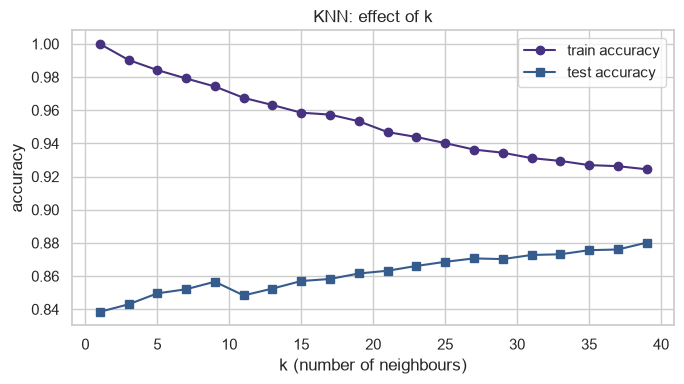

In [ ]:
ks = list(range(1, 41, 2))
tr_acc, te_acc = [], []
for k in ks:
    m = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(ks, tr_acc, "o-", label="train accuracy")
plt.plot(ks, te_acc, "s-", label="test accuracy")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.title("KNN: effect of k")
plt.legend(); plt.tight_layout(); plt.show()

With very small `k` the model memorises the training points (train accuracy is close to 1) while test accuracy is lower. This is overfitting. When `k` grows the curve becomes smoother and the gap shrinks.

### 7.3 Decision Tree: effect of depth

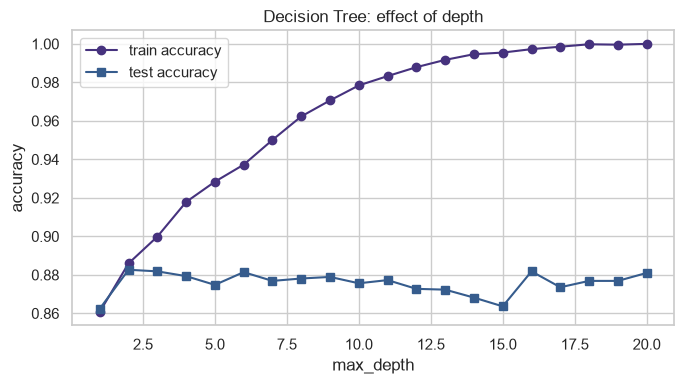

In [ ]:
depths = list(range(1, 21))
tr_acc, te_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_acc, "o-", label="train accuracy")
plt.plot(depths, te_acc, "s-", label="test accuracy")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision Tree: effect of depth")
plt.legend(); plt.tight_layout(); plt.show()

### 7.4 Naive Bayes: is its main assumption true?

Naive Bayes assumes that, once we know the class, every feature is independent of the others. In health data this is clearly not true. For example, GDP, sanitation and number of doctors all rise together. Let us see how strongly our features are correlated.

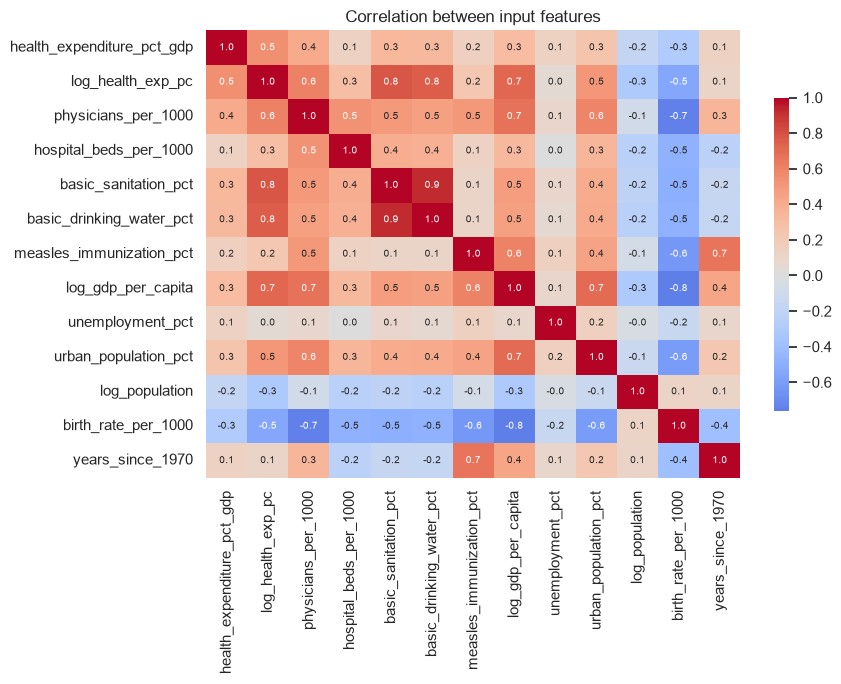

Feature pairs with |correlation| > 0.7: 7 out of 169


In [ ]:
corr = train_df[FEATURES].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": .7})
plt.title("Correlation between input features"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Feature pairs with |correlation| > 0.7:", int((pairs.abs() > 0.7).sum()), "out of", len(pairs))

## 8. Comparative analysis of the four classifiers

In [ ]:
summary = test_table.copy()
summary["Train time (s)"] = pd.Series(train_times)
summary["Overfit gap (acc)"] = gap.iloc[:, 0]
summary = summary.round(4)
display(summary)

print("Best by accuracy :", summary["Accuracy"].idxmax())
print("Best by F1-score :", summary["F1-score"].idxmax())
print("Lowest log loss  :", summary["Log loss"].idxmin())
print("Best by ROC-AUC  :", summary["ROC-AUC"].idxmax())
print("Fastest to train :", summary["Train time (s)"].idxmin())

,Accuracy,Precision,Recall,F1-score,Log loss,ROC-AUC,Train time (s),Overfit gap (acc)
SVM,0.9070,0.8895,0.9196,0.9043,0.2262,0.9672,13.7817,0.0131
Decision Tree,0.8748,0.8293,0.9291,0.8764,0.4902,0.9495,0.3702,0.0536
KNN,0.8686,0.8515,0.8780,0.8646,0.7670,0.9436,0.3367,0.0716
Naive Bayes,0.8843,0.8359,0.9429,0.8862,0.6452,0.9535,0.0415,-0.0080


Best by accuracy : SVM
Best by F1-score : SVM
Lowest log loss  : SVM
Best by ROC-AUC  : SVM
Fastest to train : Naive Bayes


### What the results tell us (test set, countries never seen before)

| Model | Accuracy | Precision | Recall | F1 | Log loss | Train-to-test drop in accuracy |
|---|---|---|---|---|---|---|
| SVM | 0.907 | 0.890 | 0.920 | 0.904 | 0.226 | 1.3 points |
| Decision Tree | 0.875 | 0.829 | 0.929 | 0.876 | 0.490 | 5.4 points |
| KNN | 0.869 | 0.852 | 0.878 | 0.865 | 0.767 | 7.2 points |
| Naive Bayes | 0.884 | 0.836 | 0.943 | 0.886 | 0.645 | -0.8 points (none) |

**1. SVM is the best overall.** It has the highest accuracy, precision, F1 and ROC-AUC, and by far the lowest loss. It also loses only about one point between training and testing, so it generalises well to new countries. The price is time: it was the slowest model to tune (about 13 seconds against under half a second for the others).

**2. Naive Bayes has the best recall (0.943), but weak precision.** It catches almost every country that is really "Good", but it also labels some "Not good" countries as "Good". Its loss (0.645) is high even though its accuracy is decent. The reason is that it multiplies probabilities of features as if they were independent, while our features (GDP, sanitation, doctors, urbanisation) move together. This makes it too confident, and confident mistakes are punished a lot by log loss. Its train and test scores are almost equal, which means it is too simple to overfit, but also too simple to go beyond about 88%.

**3. Decision Tree is easy to read but a bit unstable.** Its recall is good (0.929) while its precision is the lowest (0.829). Training accuracy keeps going up when we add depth, but test accuracy stays at about 0.87 to 0.88 (see the depth plot), so extra depth only memorises the training countries. Its loss is high because a leaf gives only a few possible probability values, and a wrong leaf is wrong with full confidence.

**4. KNN is the weakest here.** It has the lowest accuracy and F1, the highest loss, and the biggest train-to-test drop (7.2 points). KNN works by looking at similar rows, and in our data similar rows from the same country (neighbouring years) sit next to each other. On the training countries this is a big help, but a new country has no such neighbours. Using a larger `k` helped a little (see the KNN plot) because it averages over more countries.

**5. Precision and recall.** For this task, a false positive means we say a country has good life expectancy when it does not, and this could hide a country that needs help. A false negative means we flag a country that is already fine. If the worse mistake is overlooking a country that really needs help, we should look at the "Not good" class and prefer fewer false positives, and SVM has the highest precision (0.890), so it makes the fewest of them. If the worse mistake is a wrong alarm, a model with high recall such as Naive Bayes is the safer choice for finding every "Good" country.

**6. Stability.** In 5-fold grouped cross-validation the F1 of all four models differs by about 2 to 3 points, and the standard deviations (about 0.02 to 0.03) are of similar size. So the order of the middle models (Decision Tree, KNN, Naive Bayes) could change on another split, but SVM was first in both the cross-validation and the final test.

# Part B: Regression for a real-world application

## 9. The application: predicting life expectancy

**Real-world use.** Governments and organisations such as the WHO need to know which health and economic investments will improve how long people live. If we can predict life expectancy from indicators like health spending, number of doctors, clean water and income, then:

* we can estimate the life expectancy of regions where recent survey data is missing, and
* we can see which factors matter the most, which helps in planning the budget.

This time we do not turn life expectancy into classes. We predict the actual number of years, so this is a **regression** problem. We use the same features and the same country-wise train/test split as before.

Target (years) -> mean: 66.9, std: 10.3, min: 39.0, max: 83.3


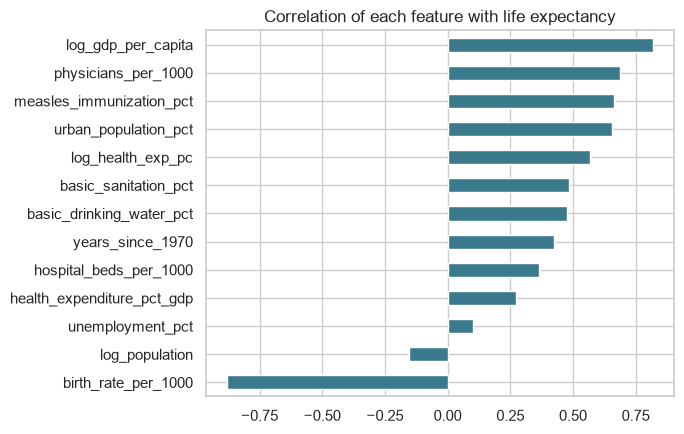

In [ ]:
yr_train = train_df["life_expectancy"].values
yr_test  = test_df["life_expectancy"].values

print("Target (years) -> mean: %.1f, std: %.1f, min: %.1f, max: %.1f" %
      (yr_train.mean(), yr_train.std(), yr_train.min(), yr_train.max()))

# how do the features relate to the target?
corr_target = train_df[FEATURES + ["life_expectancy"]].corr()["life_expectancy"].drop("life_expectancy").sort_values()
corr_target.plot(kind="barh", figsize=(7, 4.5), color="#3b7a8c")
plt.title("Correlation of each feature with life expectancy"); plt.tight_layout(); plt.show()

## 10. Regression metrics we will use

* **MAE** (Mean Absolute Error): the average mistake in years. Easy to explain.
* **MSE** (Mean Squared Error): average of the squared mistakes. Big mistakes count more.
* **RMSE**: square root of MSE, so it is again in years.
* **R² score**: how much of the variation in life expectancy the model explains. 1 is perfect, 0 means no better than always predicting the average.

In [ ]:
def regression_scores(model, X, y):
    p = model.predict(X)
    mse = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, p)}

## 11. Training the regression models

We try six models, from simple to complex:

1. **Linear Regression**: a straight-line (plane) relationship.
2. **Ridge Regression**: linear regression with a penalty that keeps the weights small.
3. **Lasso Regression**: linear regression with a penalty that can push useless weights to exactly zero.
4. **Decision Tree Regressor**
5. **KNN Regressor**
6. **Random Forest Regressor**: many trees averaged together.

In [ ]:
reg_grids = {
    "Linear Regression": (LinearRegression(), {}),
    "Ridge":  (Ridge(), {"reg__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Lasso":  (Lasso(max_iter=20000), {"reg__alpha": [0.001, 0.01, 0.1, 0.5, 1]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                      {"reg__max_depth": [4, 6, 8, 12, None], "reg__min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsRegressor(), {"reg__n_neighbors": [3, 5, 9, 15], "reg__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"reg__n_estimators": [100, 200], "reg__max_depth": [8, 14, None], "reg__min_samples_leaf": [1, 3]}),
}

reg_models, reg_times = {}, {}
for name, (est, grid) in reg_grids.items():
    pipe = Pipeline([("scale", StandardScaler()), ("reg", est)])
    t0 = time.time()
    if grid:
        s = GridSearchCV(pipe, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1 if name == "Random Forest" else -1)
        s.fit(X_train, yr_train, groups=groups_train)
        reg_models[name] = s.best_estimator_
        info = s.best_params_
    else:
        reg_models[name] = pipe.fit(X_train, yr_train)
        info = "no tuning needed"
    reg_times[name] = time.time() - t0
    print(f"{name:18s} time = {reg_times[name]:5.1f}s | settings = {info}")

Linear Regression  time =   0.0s | settings = no tuning needed
Ridge              time =   0.0s | settings = {'reg__alpha': 100}
Lasso              time =   0.0s | settings = {'reg__alpha': 0.01}


Decision Tree      time =   0.3s | settings = {'reg__max_depth': 6, 'reg__min_samples_leaf': 20}


KNN                time =   0.2s | settings = {'reg__n_neighbors': 15, 'reg__weights': 'uniform'}


Random Forest      time =  29.0s | settings = {'reg__max_depth': None, 'reg__min_samples_leaf': 3, 'reg__n_estimators': 200}


## 12. Regression results

In [ ]:
reg_test  = pd.DataFrame({n: regression_scores(m, X_test,  yr_test)  for n, m in reg_models.items()}).T
reg_train = pd.DataFrame({n: regression_scores(m, X_train, yr_train) for n, m in reg_models.items()}).T

print("TEST SET")
display(reg_test.round(4).style.highlight_min(subset=["MAE", "MSE", "RMSE"], color="#b7e4c7").highlight_max(subset=["R2"], color="#b7e4c7"))
print("TRAINING SET")
display(reg_train.round(4))

TEST SET


,MAE,MSE,RMSE,R2
Linear Regression,2.994200,17.015900,4.125000,0.838300
Ridge,2.972600,16.926900,4.114200,0.839100
Lasso,2.984500,16.992800,4.122200,0.838500
Decision Tree,3.153300,18.782400,4.333900,0.821500
KNN,3.041600,17.914900,4.232600,0.829700
Random Forest,2.741000,14.346300,3.787700,0.863700


TRAINING SET


,MAE,MSE,RMSE,R2
Linear Regression,3.1023,16.7448,4.0920,0.8421
Ridge,3.1039,16.7619,4.0941,0.8419
Lasso,3.1025,16.7505,4.0927,0.8420
Decision Tree,2.4503,11.1489,3.3390,0.8949
KNN,1.4126,4.6980,2.1675,0.9557
Random Forest,0.4490,0.6801,0.8247,0.9936


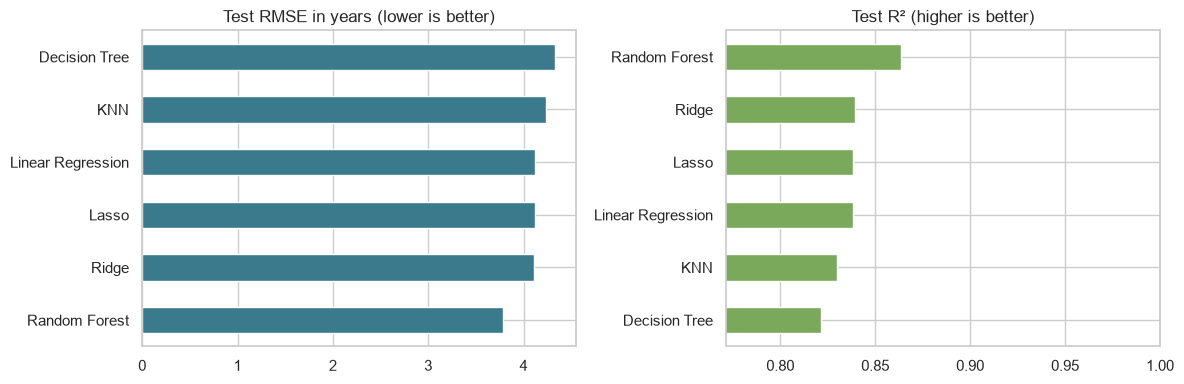

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
reg_test["RMSE"].sort_values().plot(kind="barh", ax=ax[0], color="#3b7a8c"); ax[0].set_title("Test RMSE in years (lower is better)")
reg_test["R2"].sort_values().plot(kind="barh", ax=ax[1], color="#7aa95c"); ax[1].set_title("Test R² (higher is better)")
ax[1].set_xlim(reg_test["R2"].min() - 0.05, 1.0)
plt.tight_layout(); plt.show()

### 12.1 How close are the predictions? (best model)

Best regression model on the test set: Random Forest


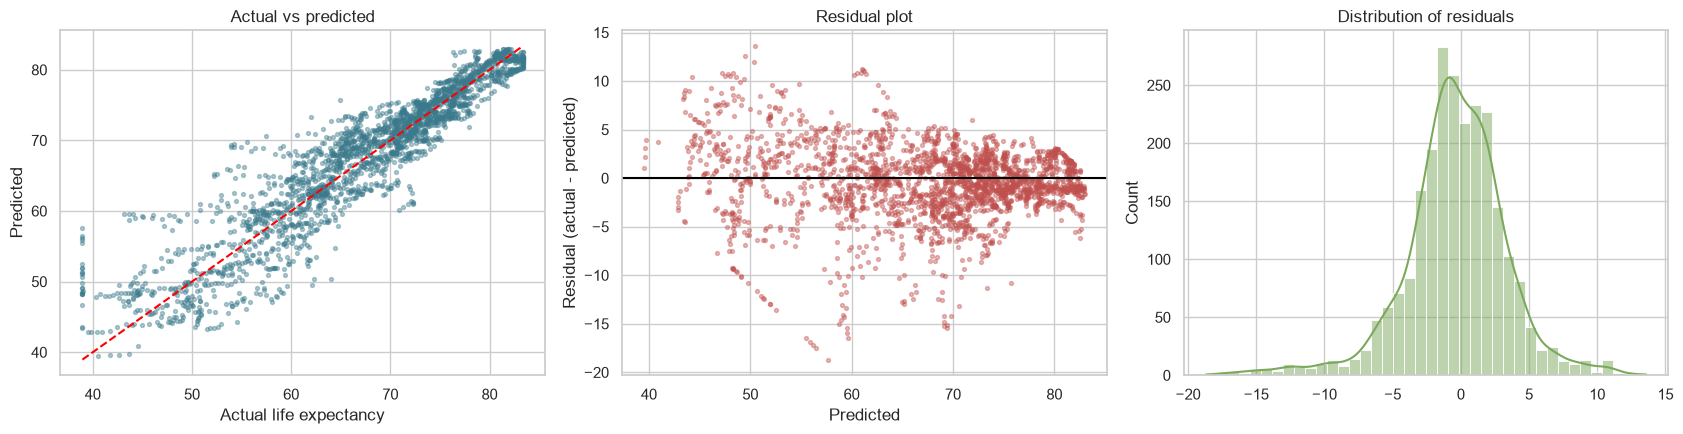

Predictions within ±2 years: 50.0%
Predictions within ±5 years: 86.0%


In [ ]:
best_reg_name = reg_test["RMSE"].idxmin()
best_reg = reg_models[best_reg_name]
pred = best_reg.predict(X_test)
resid = yr_test - pred
print("Best regression model on the test set:", best_reg_name)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(yr_test, pred, s=8, alpha=0.4, color="#3b7a8c")
lims = [yr_test.min(), yr_test.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("Actual life expectancy"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, resid, s=8, alpha=0.4, color="#c0504d"); ax[1].axhline(0, color="k")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residual plot")

sns.histplot(resid, bins=40, kde=True, ax=ax[2], color="#7aa95c"); ax[2].set_title("Distribution of residuals")
plt.tight_layout(); plt.show()

print("Predictions within ±2 years: %.1f%%" % (np.mean(np.abs(resid) <= 2) * 100))
print("Predictions within ±5 years: %.1f%%" % (np.mean(np.abs(resid) <= 5) * 100))

### 12.2 Which factors matter the most?

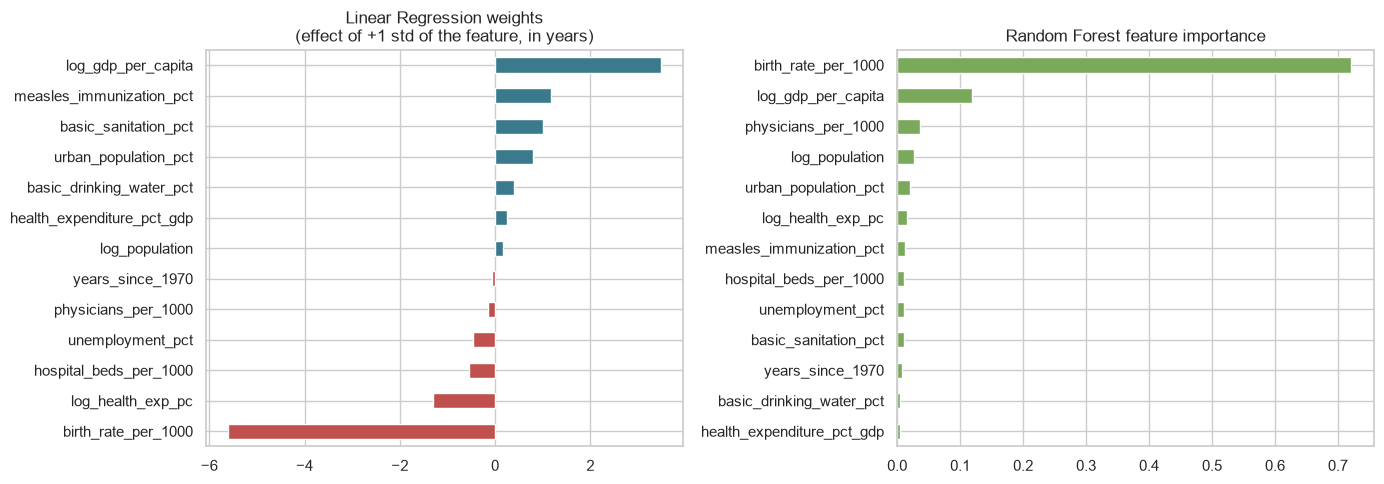

In [ ]:
lin = reg_models["Linear Regression"].named_steps["reg"]
coef = pd.Series(lin.coef_, index=FEATURES).sort_values()
rf = reg_models["Random Forest"].named_steps["reg"]
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
coef.plot(kind="barh", ax=ax[0], color=["#c0504d" if v < 0 else "#3b7a8c" for v in coef])
ax[0].set_title("Linear Regression weights\n(effect of +1 std of the feature, in years)")
rf_imp.plot(kind="barh", ax=ax[1], color="#7aa95c"); ax[1].set_title("Random Forest feature importance")
plt.tight_layout(); plt.show()

### 12.3 Where does the model make the largest errors?

In [ ]:
err = test_df[["country", "income_group", "year", "life_expectancy"]].copy()
err["predicted"] = pred
err["abs_error"] = np.abs(resid)

print("Average error by income group (years):")
display(err.groupby("income_group").abs_error.mean().round(2).sort_values().to_frame("MAE"))

print("Five biggest mistakes:")
display(err.sort_values("abs_error", ascending=False).head(5).round(2))

Average error by income group (years):


,MAE
income_group,
High income,1.71
Low income,3.27
Upper middle income,3.60
Lower middle income,3.78


Five biggest mistakes:


,country,income_group,year,life_expectancy,predicted,abs_error
10625,Timor-Leste,Lower middle income,1980,38.95,57.64,18.69
10629,Timor-Leste,Lower middle income,1984,38.95,56.47,17.52
10628,Timor-Leste,Lower middle income,1983,38.95,56.18,17.23
10627,Timor-Leste,Lower middle income,1982,38.95,55.88,16.92
10626,Timor-Leste,Lower middle income,1981,38.95,55.46,16.51


### What the regression results tell us

| Model | Test MAE (years) | Test RMSE (years) | Test R² |
|---|---|---|---|
| Linear Regression | 2.99 | 4.13 | 0.838 |
| Ridge | 2.97 | 4.11 | 0.839 |
| Lasso | 2.98 | 4.12 | 0.839 |
| Decision Tree | 3.15 | 4.33 | 0.821 |
| KNN | 3.04 | 4.23 | 0.830 |
| Random Forest | 2.74 | 3.79 | 0.864 |

* **All models explain about 82% to 86% of the variation in life expectancy** using only health, economic and population indicators. This is a good result for a problem as complex as national health.
* **Random Forest is the best on the test set** (RMSE 3.8 years, R² 0.864), but the gain over plain Linear Regression is small (about 0.3 years of RMSE). On the training set the forest reaches R² of 0.99, so it is clearly memorising part of the training data. A simple line already captures most of the pattern.
* **Ridge and Lasso give almost the same result as Linear Regression.** This tells us the plain linear model is not badly overfitted, so the penalty has little to fix.
* **Which factors matter?** Birth rate is by far the strongest: it has a correlation of -0.88 with life expectancy, and the Random Forest gives it about 72% of its total importance. GDP per capita comes next. This does not mean birth rate *causes* low life expectancy. Both are results of the same background: poverty, weak health care, little female education. The model finds a pattern, not a cause.
* **A strange sign:** in the linear model `log_health_exp_pc` has a *negative* weight although its simple correlation with life expectancy is positive (0.57). This happens because it moves together with GDP per capita, and the model shares the credit between two related features. Weights of correlated features should not be read one by one.
* **Where it fails:** the error is smallest for high-income countries (MAE about 1.7 years) and larger (3.3 to 3.8 years) for the other groups. The five biggest mistakes are all Timor-Leste in the early 1980s, where the data says 38.95 years. That same value (38.95) is repeated for several years in a row, which looks like a floor value created when we cleaned and capped the data in the first assignment, so it is probably not a real life expectancy. This is a limit of our data and we should keep it in mind.
* **In practice:** about half of the predictions are within 2 years and 86% are within 5 years of the real value.

# Part C: Gradient Descent for Linear Regression

## 13. The idea

Linear regression predicts with a line (or plane):

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

To find good values of the weights $w$ and the bias $b$ we need a measure of how wrong the line is. We use the mean squared error as the cost:

$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

Gradient descent finds the minimum of $J$ in small steps. Starting from random or zero weights, in every step we look at the slope (gradient) of the cost and then move the weights a little in the opposite direction:

$$w \leftarrow w - \alpha \, \frac{\partial J}{\partial w} \qquad b \leftarrow b - \alpha \, \frac{\partial J}{\partial b}$$

with

$$\frac{\partial J}{\partial w} = \frac{2}{m} X^T(\hat{y} - y) \qquad \frac{\partial J}{\partial b} = \frac{2}{m} \sum (\hat{y}_i - y_i)$$

where $\alpha$ is the **learning rate** (the size of each step).

We will:
1. write batch, stochastic and mini-batch gradient descent ourselves using only NumPy,
2. check that they reach the same answer as the exact formula and as scikit-learn,
3. study what happens for different learning rates, batch sizes and with or without feature scaling.

## 14. Data for gradient descent

In [ ]:
# same split as before; the scaler is fitted on the training data only
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xte = scaler.transform(X_test)
ytr, yte = yr_train, yr_test

print("Training matrix:", Xtr.shape, "| mean of first 3 columns:", Xtr.mean(axis=0)[:3].round(3), "| std:", Xtr.std(axis=0)[:3].round(3))

Training matrix: (9495, 13) | mean of first 3 columns: [0. 0. 0.] | std: [1. 1. 1.]


## 15. Writing gradient descent from scratch

One function handles all three versions. The only difference is *how many rows* we use to calculate each gradient:

* **Batch GD**: all rows in every step (`batch_size = m`)
* **Stochastic GD (SGD)**: one random row per step (`batch_size = 1`)
* **Mini-batch GD**: a small group of rows per step (for example 32)

We save the training cost after each epoch (one full pass over the data) so that we can draw the learning curve later.

In [ ]:
def mse_cost(X, y, w, b):
    err = X @ w + b - y
    return np.mean(err ** 2)

def gradient_descent(X, y, lr=0.1, epochs=100, batch_size=None, seed=0, X_val=None, y_val=None):
    """Linear regression trained with gradient descent.
    batch_size=None -> full batch, 1 -> stochastic, k -> mini-batch of k rows."""
    rng = np.random.default_rng(seed)
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    bs = m if batch_size is None else batch_size

    history = {"cost": [mse_cost(X, y, w, b)], "val_cost": [], "w": [w.copy()], "b": [b]}
    if X_val is not None:
        history["val_cost"].append(mse_cost(X_val, y_val, w, b))

    for epoch in range(epochs):
        order = rng.permutation(m) if bs < m else np.arange(m)
        for start in range(0, m, bs):
            idx = order[start:start + bs]
            Xb, yb = X[idx], y[idx]
            error = Xb @ w + b - yb
            grad_w = 2 * Xb.T @ error / len(idx)
            grad_b = 2 * error.mean()
            w = w - lr * grad_w
            b = b - lr * grad_b
            if not np.all(np.isfinite(w)):          # the learning rate was too big, stop early
                history["cost"].append(np.inf)
                return w, b, history
        history["cost"].append(mse_cost(X, y, w, b))
        history["w"].append(w.copy()); history["b"].append(b)
        if X_val is not None:
            history["val_cost"].append(mse_cost(X_val, y_val, w, b))
    return w, b, history

## 16. First check: does it find the right answer?

For linear regression there is also an exact solution, the **normal equation**:

$$\theta = (X^T X)^{-1} X^T y$$

and scikit-learn's `LinearRegression` gives the same thing. If our gradient descent is correct, its weights should be almost identical to these.

In [ ]:
# exact solution (normal equation) with a column of ones for the bias
Xb_tr = np.c_[np.ones(len(Xtr)), Xtr]
theta = np.linalg.solve(Xb_tr.T @ Xb_tr, Xb_tr.T @ ytr)
b_exact, w_exact = theta[0], theta[1:]

sk = LinearRegression().fit(Xtr, ytr)
w_gd, b_gd, hist_gd = gradient_descent(Xtr, ytr, lr=0.1, epochs=300)

compare = pd.DataFrame({"Normal equation": w_exact, "sklearn": sk.coef_, "Our gradient descent": w_gd}, index=FEATURES)
compare.loc["bias (intercept)"] = [b_exact, sk.intercept_, b_gd]
display(compare.round(4))

print("Largest difference between GD and the exact weights:", np.abs(w_gd - w_exact).max().round(6))
print("Final training MSE -> exact: %.4f | GD: %.4f" % (mse_cost(Xtr, ytr, w_exact, b_exact), hist_gd["cost"][-1]))

,Normal equation,sklearn,Our gradient descent
health_expenditure_pct_gdp,0.2493,0.2493,0.2451
log_health_exp_pc,-1.2944,-1.2944,-1.2777
physicians_per_1000,-0.1479,-0.1479,-0.1497
hospital_beds_per_1000,-0.5575,-0.5575,-0.5566
basic_sanitation_pct,0.9995,0.9995,0.9899
basic_drinking_water_pct,0.3951,0.3951,0.3957
measles_immunization_pct,1.1673,1.1673,1.1708
log_gdp_per_capita,3.4908,3.4908,3.4773
unemployment_pct,-0.4720,-0.4720,-0.4715
urban_population_pct,0.7902,0.7902,0.7924


Largest difference between GD and the exact weights: 0.016638
Final training MSE -> exact: 16.7448 | GD: 16.7448


The numbers match to several decimal places, so our implementation is correct.

## 17. Learning curve

We plot the training cost after each epoch. A good learning curve falls quickly at the start and then becomes flat. The flat part means the algorithm has **converged** (found the bottom).

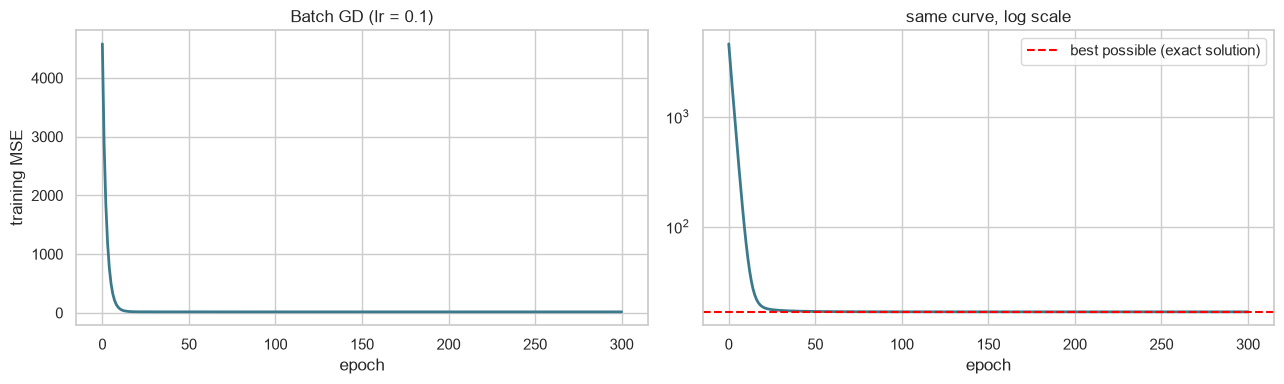

Cost at epoch 0 : 4579.16
Cost at epoch 10: 70.81
Cost at epoch 50: 16.88
Cost at epoch 300: 16.74


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_gd["cost"], color="#3b7a8c", lw=2)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training MSE"); ax[0].set_title("Batch GD (lr = 0.1)")
ax[1].plot(hist_gd["cost"], color="#3b7a8c", lw=2)
ax[1].axhline(mse_cost(Xtr, ytr, w_exact, b_exact), color="red", ls="--", label="best possible (exact solution)")
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("same curve, log scale"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Cost at epoch 0 :", round(hist_gd["cost"][0], 2))
print("Cost at epoch 10:", round(hist_gd["cost"][10], 2))
print("Cost at epoch 50:", round(hist_gd["cost"][50], 2))
print("Cost at epoch 300:", round(hist_gd["cost"][-1], 2))

## 18. Seeing gradient descent move (one feature)

With several features we cannot draw the cost. So for this picture we use only one feature, `log_gdp_per_capita`. The cost is then a bowl-shaped surface over two numbers (weight `w` and bias `b`). The red path is the route taken by gradient descent. The second plot shows how the fitted line improves as training goes on.

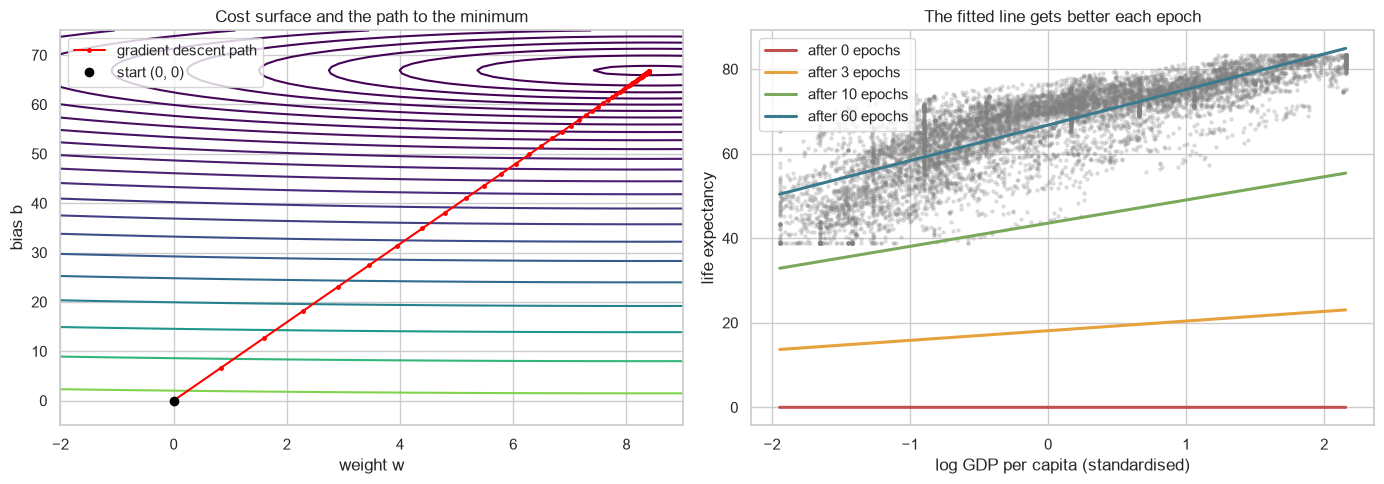

In [ ]:
j = FEATURES.index("log_gdp_per_capita")
x1, x1_te = Xtr[:, [j]], Xte[:, [j]]

w1, b1, h1 = gradient_descent(x1, ytr, lr=0.05, epochs=60)
path_w = np.array([w[0] for w in h1["w"]]); path_b = np.array(h1["b"])

# cost surface
ws = np.linspace(-2, 9, 120); bs_ = np.linspace(-5, 75, 120)
W, B = np.meshgrid(ws, bs_)
Z = np.array([[mse_cost(x1, ytr, np.array([wv]), bv) for wv in ws] for bv in bs_])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cs = ax[0].contour(W, B, Z, levels=np.geomspace(Z.min() + 1, Z.max(), 25), cmap="viridis")
ax[0].plot(path_w, path_b, "r.-", lw=1.5, ms=5, label="gradient descent path")
ax[0].plot(path_w[0], path_b[0], "ko", label="start (0, 0)")
ax[0].set_xlabel("weight w"); ax[0].set_ylabel("bias b"); ax[0].set_title("Cost surface and the path to the minimum"); ax[0].legend()

order = np.argsort(x1[:, 0])
ax[1].scatter(x1[:, 0], ytr, s=5, alpha=0.2, color="grey")
for ep, col in [(0, "#c0504d"), (3, "#e6a23c"), (10, "#7aa95c"), (60, "#3b7a8c")]:
    ax[1].plot(x1[order, 0], x1[order, 0] * h1["w"][ep][0] + h1["b"][ep], color=col, lw=2.2, label=f"after {ep} epochs")
ax[1].set_xlabel("log GDP per capita (standardised)"); ax[1].set_ylabel("life expectancy"); ax[1].set_title("The fitted line gets better each epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 19. Effect of the learning rate

The learning rate $\alpha$ is the most important setting. We try five values:

* too small, so learning is very slow,
* a good value, which converges smoothly,
* too large, so the weights jump over the minimum and the cost may explode.

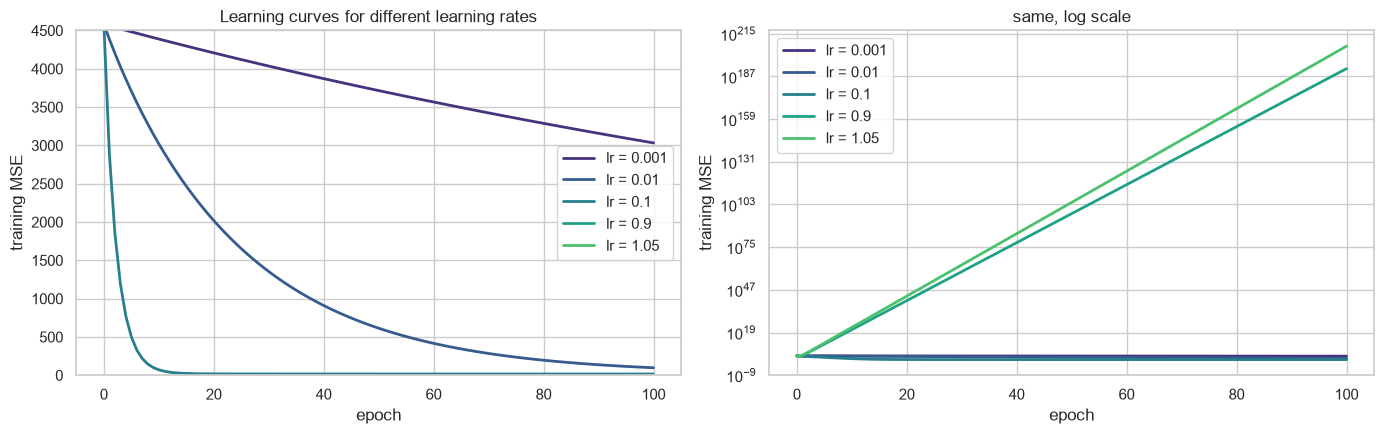

,learning rate,final training MSE,epochs to get within 1% of best,status
0,0.001,3.032528e+03,NaN,still learning
1,0.010,9.797700e+01,NaN,still learning
2,0.100,1.676100e+01,47.0,converged
3,0.900,1.309961e+192,NaN,diverged
4,1.050,7.652462e+206,NaN,diverged


In [ ]:
lrs = [0.001, 0.01, 0.1, 0.9, 1.05]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
rows = []
for lr in lrs:
    w, b, h = gradient_descent(Xtr, ytr, lr=lr, epochs=100)
    c = np.array(h["cost"])
    ax[0].plot(c, lw=2, label=f"lr = {lr}")
    ax[1].plot(c, lw=2, label=f"lr = {lr}")
    first_close = np.argmax(c <= mse_cost(Xtr, ytr, w_exact, b_exact) * 1.01) if (c <= mse_cost(Xtr, ytr, w_exact, b_exact) * 1.01).any() else None
    rows.append({"learning rate": lr, "final training MSE": c[-1], "epochs to get within 1% of best": first_close,
                 "status": "diverged" if (not np.isfinite(c[-1]) or c[-1] > c[0]) else ("converged" if first_close is not None else "still learning")})
ax[0].set_ylim(0, 4500); ax[0].set_title("Learning curves for different learning rates")
ax[1].set_yscale("log"); ax[1].set_title("same, log scale")
for a in ax: a.set_xlabel("epoch"); a.set_ylabel("training MSE"); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

**What we see**

* `lr = 0.001` is far too small. After 100 epochs the cost is still above 3000 and it has barely started to come down.
* `lr = 0.01` is also slow. It is still learning at epoch 100 (cost about 98).
* `lr = 0.1` is a good value. The cost drops very quickly (from 4579 to about 71 within 10 epochs) and it is within 1% of the best possible value after 47 epochs.
* `lr = 0.9` and `lr = 1.05` are too big. Each step jumps over the bottom of the bowl and lands higher on the other side, so the cost grows at every step and finally explodes to a number with 190+ digits. This is called divergence.

So the learning rate has a "sweet spot". Too small wastes time, too big breaks the algorithm. For this problem the safe upper limit lies somewhere between 0.1 and 0.9.

## 20. Batch vs Stochastic vs Mini-batch

Now we compare the three versions with the same learning-rate idea. SGD and mini-batch update the weights many times per epoch, so we use a smaller learning rate for them to keep the noise down.

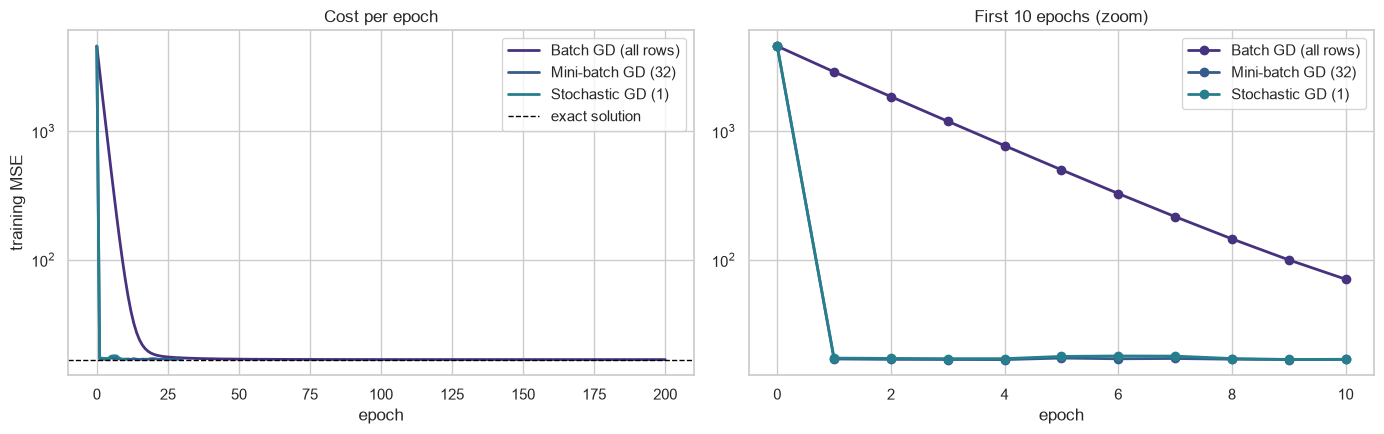

,Method,epochs,weight updates,final train MSE,test MSE,time (s),max weight error vs exact
0,Batch GD (all rows),200,200,16.7456,17.0427,0.0315,0.0712
1,Mini-batch GD (32),30,8910,16.7951,17.2351,0.0500,0.0725
2,Stochastic GD (1),10,94950,16.8988,17.2016,0.4911,0.1845


In [ ]:
configs = {
    "Batch GD (all rows)": dict(lr=0.1,   batch_size=None, epochs=200),
    "Mini-batch GD (32)":  dict(lr=0.02,  batch_size=32,   epochs=30),
    "Stochastic GD (1)":   dict(lr=0.002, batch_size=1,    epochs=10),
}
runs = {}
for name, cfg in configs.items():
    t0 = time.time()
    w, b, h = gradient_descent(Xtr, ytr, X_val=Xte, y_val=yte, **cfg)
    runs[name] = dict(w=w, b=b, h=h, time=time.time() - t0, cfg=cfg)

best_cost = mse_cost(Xtr, ytr, w_exact, b_exact)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in runs.items():
    ax[0].plot(r["h"]["cost"], lw=2, label=name)
ax[0].axhline(best_cost, color="k", ls="--", lw=1, label="exact solution")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training MSE"); ax[0].set_title("Cost per epoch"); ax[0].legend()

for name, r in runs.items():
    ax[1].plot(r["h"]["cost"][:11], "o-", lw=2, label=name)
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("First 10 epochs (zoom)"); ax[1].legend()
plt.tight_layout(); plt.show()

rows = []
for name, r in runs.items():
    rows.append({"Method": name, "epochs": r["cfg"]["epochs"], "weight updates": r["cfg"]["epochs"] * (1 if r["cfg"]["batch_size"] is None else int(np.ceil(len(Xtr) / r["cfg"]["batch_size"]))),
                 "final train MSE": r["h"]["cost"][-1], "test MSE": r["h"]["val_cost"][-1], "time (s)": r["time"],
                 "max weight error vs exact": np.abs(r["w"] - w_exact).max()})
pd.DataFrame(rows).round(4)

**What we see**

* All three methods end up at almost the same place. Their final training MSE (16.75 to 16.90) is very close to the best possible value (16.74), and their test MSE (17.0 to 17.2) is also close.
* **Batch GD** has the smoothest curve and the most accurate weights (largest weight error vs exact: 0.07). Each step is exact, but each step uses the full data. It needs 200 epochs, which here is still only 0.03 seconds because our data is small. On a very large dataset one step would be slow.
* **Stochastic GD** makes one update per row, which is 94,950 updates in 10 epochs. It makes a lot of progress in each epoch (see the zoom plot) but its path is noisy and it keeps jumping around the minimum instead of settling. Its weight error is the largest (0.18), and it is the slowest in our run because Python loops over single rows.
* **Mini-batch GD** is in the middle. It is faster per epoch than SGD and less noisy, and it is the standard choice for large problems, in particular deep learning, because it also works well on GPUs.

In short: batch is smooth but expensive per step, stochastic is cheap per step but noisy, and mini-batch gives a good balance of both.

## 21. Why feature scaling matters for gradient descent

In the first assignment we scaled our features. Here we can see the reason. If one feature is in millions (population) and another is between 0 and 1, the cost surface becomes a long, narrow valley. Gradient descent then zig-zags and has to use a tiny learning rate. We train on the *unscaled* data and compare it with the scaled data.

Feature ranges before scaling:


,log_gdp_per_capita,physicians_per_1000,basic_sanitation_pct,years_since_1970
min,4.78,0.02,8.7,0.00
max,11.41,5.17,100.0,54.00
std,1.62,1.30,25.0,15.87


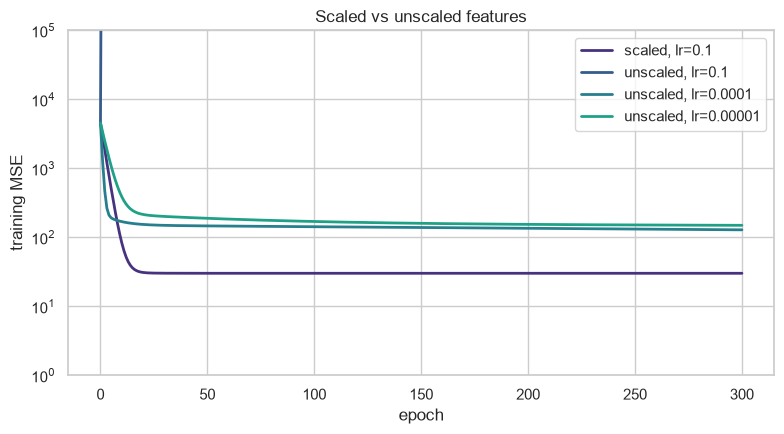

In [ ]:
# unscaled data: use only 4 features so the picture is easy to read, same learning rate for both
cols = ["log_gdp_per_capita", "physicians_per_1000", "basic_sanitation_pct", "years_since_1970"]
ci = [FEATURES.index(c) for c in cols]
Xraw = X_train[:, ci]
Xsc  = Xtr[:, ci]
print("Feature ranges before scaling:"); display(pd.DataFrame(Xraw, columns=cols).describe().loc[["min", "max", "std"]].round(2))

tests = {"scaled, lr=0.1": (Xsc, 0.1), "unscaled, lr=0.1": (Xraw, 0.1), "unscaled, lr=0.0001": (Xraw, 0.0001), "unscaled, lr=0.00001": (Xraw, 0.00001)}
plt.figure(figsize=(8, 4.5))
for name, (Xin, lr) in tests.items():
    _, _, h = gradient_descent(Xin, ytr, lr=lr, epochs=300)
    c = np.array(h["cost"]); c = np.where(np.isfinite(c), c, np.nan)
    plt.plot(c, lw=2, label=name)
plt.yscale("log"); plt.ylim(top=1e5); plt.xlabel("epoch"); plt.ylabel("training MSE")
plt.title("Scaled vs unscaled features"); plt.legend(); plt.tight_layout(); plt.show()

**What we see**

* On the **scaled** data, `lr = 0.1` works well and, after 300 epochs, the cost (30.12) matches the exact solution for these four features.
* On the **unscaled** data the same `lr = 0.1` **explodes**, because features such as `basic_sanitation_pct` (values up to 100) and `years_since_1970` (up to 54) give very large gradients.
* The only way to make unscaled data stable is to use a much smaller learning rate (0.0001 or 0.00001), but then learning is so slow that after 300 epochs the cost is still 128 or 149, far from the best value of 30.

This is the reason we do feature scaling: it lets us use one comfortable learning rate for all weights and reach the minimum much faster.

## 22. Final test of our gradient descent model

We compare the model trained by our own gradient descent with the exact solution and with scikit-learn on the unseen test countries.

In [ ]:
def scores_from_weights(w, b, X, y):
    p = X @ w + b
    mse = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, p)}

final = pd.DataFrame({
    "Batch GD (ours)":      scores_from_weights(runs["Batch GD (all rows)"]["w"], runs["Batch GD (all rows)"]["b"], Xte, yte),
    "Mini-batch GD (ours)": scores_from_weights(runs["Mini-batch GD (32)"]["w"],  runs["Mini-batch GD (32)"]["b"],  Xte, yte),
    "Stochastic GD (ours)": scores_from_weights(runs["Stochastic GD (1)"]["w"],   runs["Stochastic GD (1)"]["b"],   Xte, yte),
    "Normal equation":      scores_from_weights(w_exact, b_exact, Xte, yte),
    "sklearn LinearRegression": scores_from_weights(sk.coef_, sk.intercept_, Xte, yte),
}).T
display(final.round(4))

,MAE,MSE,RMSE,R2
Batch GD (ours),2.9941,17.0427,4.1283,0.8380
Mini-batch GD (ours),3.0231,17.2351,4.1515,0.8362
Stochastic GD (ours),2.9939,17.2016,4.1475,0.8365
Normal equation,2.9942,17.0159,4.1250,0.8383
sklearn LinearRegression,2.9942,17.0159,4.1250,0.8383


### Conclusion of Part C

* Our NumPy gradient descent reaches the same weights and nearly the same test scores as the exact formula and scikit-learn (R² 0.836 to 0.838 against 0.838). The tiny differences come from stopping after a limited number of epochs.
* The learning rate decides everything: 0.1 works, 0.001 and 0.01 are too slow, 0.9 and above diverge.
* Batch GD is smooth, SGD is noisy and mini-batch is a practical balance.
* Feature scaling is not optional for gradient descent. Without it we need a tiny learning rate and training becomes very slow, or it diverges.
* For a small linear problem like this one the exact formula is the quickest way. Gradient descent becomes valuable when the data is too large for matrix inversion or when the model has no closed-form solution (logistic regression, neural networks).

# Part D: Final summary

## 23. Suitability of each algorithm for different classification tasks

| Algorithm | Strengths | Weaknesses | Suitable when |
|---|---|---|---|
| **SVM (RBF)** | Best accuracy, F1 and loss here. Handles many correlated numeric features. Little overfitting. | Slowest to train (grows quickly with rows). Needs scaling. Hard to explain. Probabilities need extra calibration. | The dataset is small or medium, the features are numeric, and accuracy matters more than speed or explanation. |
| **Decision Tree** | Very easy to explain with simple if-then rules. Needs no scaling. Fast. Shows feature importance. | Overfits when it is deep. Probabilities are rough, so loss is high. Small changes in data can change the tree. | A decision must be explained to people (for example a health ministry), or the data has mixed feature types. |
| **KNN** | No training step, very simple idea, good with local patterns. | Prediction is slow on large data. Sensitive to scaling and to `k`. Suffered most from repeated rows of the same country. | The data is small, there is no dependence between rows, and we want a quick baseline. |
| **Naive Bayes** | Extremely fast, almost no tuning, no overfitting, high recall. | Wrong independence assumption for correlated features, so probabilities are overconfident and loss is high. | There are very many features (text, spam filters), little data, or a quick baseline and high recall is needed. |

## 24. Overall conclusions

1. **Classification.** Using only health-system and economic indicators, we can tell whether life expectancy is above 70 years with about 87% to 91% accuracy for countries the model has never seen. **SVM** was the best model on every important measure, Naive Bayes was the fastest and the best at recall, the Decision Tree is the one that is easiest to explain, and KNN came last because of the repeated yearly rows of each country.
2. **Regression.** The same indicators predict life expectancy in years with an average error of about 3 years. **Random Forest** was the best (R² 0.864), but a simple linear model was almost as good (R² 0.838), so a simple model is a reasonable choice when we want something understandable. Birth rate and GDP per capita are the most informative features.
3. **Gradient descent.** Our own implementation matches the exact solution. Its speed depends on a well-chosen learning rate and on scaled features. Batch, stochastic and mini-batch reach the same answer in different ways.
4. **Honest evaluation matters.** By splitting by country and by removing outcome-like columns we avoided leakage. If we had split randomly, KNN and the Decision Tree would have looked much better than they really are.
5. **Limits.** The data contains imputed and capped values from our first assignment (for example the repeated 38.95 years), so the model's results for the poorest countries and early years are less trustworthy. The 70-year threshold is a choice, and different thresholds could change the ranking slightly.

### Possible next steps
* Try a probability calibration for SVM, or lower the decision threshold to improve recall.
* Try gradient boosting models and compare them with Random Forest.
* Use time-based validation (train on earlier years, test on later years).